In [ ]:
import pandas as pd
import pickle

# Load the pickle file
with open('/content/best_features_gwo.pkl', 'rb') as f:
    best_features = pickle.load(f)

print("Features loaded from pickle file:")
print(best_features)

# Load the CSV file, trying a semicolon as a separator due to parsing error
try:
    df = pd.read_csv('/content/dataset_bersih.csv', sep=';')
except pd.errors.ParserError:
    print("Could not parse with semicolon, trying default (comma).")
    df = pd.read_csv('/content/dataset_bersih.csv')

print("\nOriginal CSV DataFrame head:")
display(df.head())

# Filter the DataFrame using the features from the pickle file
# Ensure all best_features are present in the DataFrame columns
# If a feature is not found, it will be skipped with a warning.
existing_features = [col for col in best_features['names'] if col in df.columns]

if not existing_features:
    print("\nWarning: None of the features from the pickle file were found in the CSV dataset. An empty DataFrame will be returned.")
    df_filtered = pd.DataFrame()
else:
    df_filtered = df[existing_features]

print("\nFiltered CSV DataFrame head based on pickle features:")
display(df_filtered.head())

Features loaded from pickle file:
{'indices': [3, 5, 10, 12, 22, 24, 26, 29], 'names': ['area_mean', 'compactness_mean', 'radius_se', 'perimeter_se', 'perimeter_worst', 'smoothness_worst', 'concavity_worst', 'fractal_dimension_worst']}

Original CSV DataFrame head:


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,1,0.521037,0.022658,0.545989,0.363733,0.593753,0.792037,0.703140,0.731113,0.686364,...,0.620776,0.141525,0.668310,0.450698,0.601136,0.619292,0.568610,0.912027,0.598462,0.418864
1,1,0.643144,0.272574,0.615783,0.501591,0.289880,0.181768,0.203608,0.348757,0.379798,...,0.606901,0.303571,0.539818,0.435214,0.347553,0.154563,0.192971,0.639175,0.233590,0.222878
2,1,0.601496,0.390260,0.595743,0.449417,0.514309,0.431017,0.462512,0.635686,0.509596,...,0.556386,0.360075,0.508442,0.374508,0.483590,0.385375,0.359744,0.835052,0.403706,0.213433
3,1,0.210090,0.360839,0.233501,0.102906,0.811321,0.811361,0.565604,0.522863,0.776263,...,0.248310,0.385928,0.241347,0.094008,0.915472,0.814012,0.548642,0.884880,1.000000,0.773711
4,1,0.629893,0.156578,0.630986,0.489290,0.430351,0.347893,0.463918,0.518390,0.378283,...,0.519744,0.123934,0.506948,0.341575,0.437364,0.172415,0.319489,0.558419,0.157500,0.142595



Filtered CSV DataFrame head based on pickle features:


,area_mean,compactness_mean,radius_se,perimeter_se,perimeter_worst,smoothness_worst,concavity_worst,fractal_dimension_worst
0,0.363733,0.792037,0.356147,0.369034,0.668310,0.601136,0.568610,0.418864
1,0.501591,0.181768,0.156437,0.124440,0.539818,0.347553,0.192971,0.222878
2,0.449417,0.431017,0.229622,0.180370,0.508442,0.483590,0.359744,0.213433
3,0.102906,0.811361,0.139091,0.126655,0.241347,0.915472,0.548642,0.773711
4,0.489290,0.347893,0.233822,0.220563,0.506948,0.437364,0.319489,0.142595


In [ ]:
y = df['diagnosis']
X = df_filtered

print("Shape of X (features):")
print(X.shape)
print("\nShape of y (target):")
print(y.shape)
print("\nFirst 5 rows of X:")
display(X.head())
print("\nFirst 5 values of y:")
display(y.head())

Shape of X (features):
(569, 8)

Shape of y (target):
(569,)

First 5 rows of X:


,area_mean,compactness_mean,radius_se,perimeter_se,perimeter_worst,smoothness_worst,concavity_worst,fractal_dimension_worst
0,0.363733,0.792037,0.356147,0.369034,0.668310,0.601136,0.568610,0.418864
1,0.501591,0.181768,0.156437,0.124440,0.539818,0.347553,0.192971,0.222878
2,0.449417,0.431017,0.229622,0.180370,0.508442,0.483590,0.359744,0.213433
3,0.102906,0.811361,0.139091,0.126655,0.241347,0.915472,0.548642,0.773711
4,0.489290,0.347893,0.233822,0.220563,0.506948,0.437364,0.319489,0.142595



First 5 values of y:


,diagnosis
0,1
1,1
2,1
3,1
4,1


In [ ]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (455, 8)
Shape of X_test: (114, 8)
Shape of y_train: (455,)
Shape of y_test: (114,)


In [ ]:
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import numpy as np # Import numpy for NaN handling
import pandas as pd # Import pandas for to_numeric and fillna

# Ensure all feature columns are numeric and handle potential NaN values
# This step is crucial if original data might have non-numeric entries parsed as 'object'
# that were not caught earlier or are introduced by data manipulations.
for col in X_train.columns:
    # Convert column to numeric, coercing errors to NaN
    X_train[col] = pd.to_numeric(X_train[col], errors='coerce')
    X_test[col] = pd.to_numeric(X_test[col], errors='coerce')

    # Fill NaN values with the mean of the column (from the training set)
    # It's important to use training set mean to avoid data leakage
    if X_train[col].isnull().any():
        mean_val = X_train[col].mean()
        X_train[col] = X_train[col].fillna(mean_val)
        X_test[col] = X_test[col].fillna(mean_val) # Apply the same mean to test set

print("Data preprocessing complete: Numeric conversion and NaN handling applied.")
print("Ready to train individual models with specified optimizations.")

Data preprocessing complete: Numeric conversion and NaN handling applied.
Ready to train individual models with specified optimizations.


### Penskalaan Fitur

Penskalaan fitur adalah langkah penting dalam pra-pemrosesan data untuk banyak algoritma pembelajaran mesin. Ini memastikan bahwa tidak ada fitur yang mendominasi yang lain hanya karena skala numeriknya yang lebih besar, dan membantu algoritma yang sensitif terhadap skala fitur (seperti KNN, SVM, dan ANN) bekerja lebih baik. Karena model `rf_model_r5` dilatih tanpa penskalaan eksplisit, jika Anda ingin model ini (atau model lainnya) memanfaatkan data yang diskalakan, Anda harus melatih ulang model setelah langkah ini.

Di sini, kita akan menggunakan `StandardScaler` untuk menstandarisasi fitur, yaitu mengubahnya sehingga rata-rata 0 dan variansi 1.

In [ ]:
from sklearn.preprocessing import StandardScaler
import pickle

# Inisialisasi StandardScaler
scaler = StandardScaler()

# Paskan scaler hanya pada data pelatihan untuk menghindari kebocoran data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Konversi kembali ke DataFrame untuk menjaga nama kolom
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

print("Data pelatihan dan pengujian telah diskalakan.")
print("Bentuk X_train_scaled_df:", X_train_scaled_df.shape)
print("Bentuk X_test_scaled_df:", X_test_scaled_df.shape)
display(X_train_scaled_df.head())

# Simpan objek scaler
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print("Objek 'scaler.pkl' telah disimpan.")

# Sekarang, jika Anda ingin melatih ulang model Anda dengan data yang diskalakan,
# Anda dapat menggunakan X_train_scaled_df dan X_test_scaled_df.
# Contoh: rf_model_r5_scaled = RandomForestClassifier(...)
#         rf_model_r5_scaled.fit(X_train_scaled_df, y_train)

Data pelatihan dan pengujian telah diskalakan.
Bentuk X_train_scaled_df: (455, 8)
Bentuk X_test_scaled_df: (114, 8)


,area_mean,compactness_mean,radius_se,perimeter_se,perimeter_worst,smoothness_worst,concavity_worst,fractal_dimension_worst
68,-1.139118,0.718921,-0.263800,-0.470414,-1.247920,0.722894,4.672828,1.886450
181,1.851973,3.426275,0.805319,0.751957,2.081617,0.761928,1.928621,2.497838
63,-1.109785,-0.307355,0.027521,-0.120958,-1.245220,-1.438693,-0.644911,0.057894
248,-0.866944,-0.596788,-0.538505,-0.657950,-0.873572,0.796624,-0.774950,-0.134497
60,-0.965942,-0.439002,0.402278,0.219314,-1.117138,-0.174876,-1.209146,-0.205732


Objek 'scaler.pkl' telah disimpan.


In [ ]:
# Initialize dictionary to store results for optimized models
results_optimized = {}

# --- K-Nearest Neighbors (KNN) with k=3 and Euclidean distance ---
print("--- Training and evaluating K-Nearest Neighbors (KNN) ---")
knn_model = KNeighborsClassifier(n_neighbors=3, metric='euclidean')
knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)
y_pred_proba_knn = knn_model.predict_proba(X_test)[:, 1]

accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
roc_auc_knn = roc_auc_score(y_test, y_pred_proba_knn)

results_optimized["K-Nearest Neighbors (KNN)"] = {
    "Accuracy": accuracy_knn,
    "Precision": precision_knn,
    "Recall": recall_knn,
    "F1-Score": f1_knn,
    "ROC AUC": roc_auc_knn
}

print(f"Accuracy: {accuracy_knn:.4f}")
print(f"Precision: {precision_knn:.4f}")
print(f"Recall: {recall_knn:.4f}")
print(f"F1-Score: {f1_knn:.4f}")
print(f"ROC AUC: {roc_auc_knn:.4f}")
print("-" * 40)

--- Training and evaluating K-Nearest Neighbors (KNN) ---
Accuracy: 0.9649
Precision: 0.9535
Recall: 0.9535
F1-Score: 0.9535
ROC AUC: 0.9954
----------------------------------------


In [ ]:
# --- Artificial Neural Network (ANN) with Hidden Layers: (16), Opt: Adam ---
print("--- Training and evaluating Artificial Neural Network (ANN) ---")
ann_model = MLPClassifier(hidden_layer_sizes=(16,), activation='relu', solver='adam', max_iter=500, random_state=42)
ann_model.fit(X_train, y_train)

y_pred_ann = ann_model.predict(X_test)
y_pred_proba_ann = ann_model.predict_proba(X_test)[:, 1]

accuracy_ann = accuracy_score(y_test, y_pred_ann)
precision_ann = precision_score(y_test, y_pred_ann)
recall_ann = recall_score(y_test, y_pred_ann)
f1_ann = f1_score(y_test, y_pred_ann)
roc_auc_ann = roc_auc_score(y_test, y_pred_proba_ann)

results_optimized["Artificial Neural Network (ANN)"] = {
    "Accuracy": accuracy_ann,
    "Precision": precision_ann,
    "Recall": recall_ann,
    "F1-Score": f1_ann,
    "ROC AUC": roc_auc_ann
}

print(f"Accuracy: {accuracy_ann:.4f}")
print(f"Precision: {precision_ann:.4f}")
print(f"Recall: {recall_ann:.4f}")
print(f"F1-Score: {f1_ann:.4f}")
print(f"ROC AUC: {roc_auc_ann:.4f}")
print("-" * 40)

--- Training and evaluating Artificial Neural Network (ANN) ---
Accuracy: 0.9825
Precision: 1.0000
Recall: 0.9535
F1-Score: 0.9762
ROC AUC: 0.9997
----------------------------------------


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
# --- XGBoost with n_estimators: 100, Learning Rate: 0.1 ---
print("--- Training and evaluating XGBoost ---")
xgb_model = xgb.XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42, use_label_encoder=False, eval_metric='logloss')
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)
y_pred_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
roc_auc_xgb = roc_auc_score(y_test, y_pred_proba_xgb)

results_optimized["XGBoost"] = {
    "Accuracy": accuracy_xgb,
    "Precision": precision_xgb,
    "Recall": recall_xgb,
    "F1-Score": f1_xgb,
    "ROC AUC": roc_auc_xgb
}

print(f"Accuracy: {accuracy_xgb:.4f}")
print(f"Precision: {precision_xgb:.4f}")
print(f"Recall: {recall_xgb:.4f}")
print(f"F1-Score: {f1_xgb:.4f}")
print(f"ROC AUC: {roc_auc_xgb:.4f}")
print("-" * 40)

--- Training and evaluating XGBoost ---
Accuracy: 0.9825
Precision: 0.9767
Recall: 0.9767
F1-Score: 0.9767
ROC AUC: 0.9987
----------------------------------------


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [07:42:08] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [ ]:
# --- Support Vector Machine (SVM) with Kernel: Linear, C: 1.0 ---
print("--- Training and evaluating Support Vector Machine (SVM) ---")
svm_model = SVC(kernel='linear', C=1.0, probability=True, random_state=42)
svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)
y_pred_proba_svm = svm_model.predict_proba(X_test)[:, 1]

accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm)
recall_svm = recall_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)
roc_auc_svm = roc_auc_score(y_test, y_pred_proba_svm)

results_optimized["Support Vector Machine (SVM)"] = {
    "Accuracy": accuracy_svm,
    "Precision": precision_svm,
    "Recall": recall_svm,
    "F1-Score": f1_svm,
    "ROC AUC": roc_auc_svm
}

print(f"Accuracy: {accuracy_svm:.4f}")
print(f"Precision: {precision_svm:.4f}")
print(f"Recall: {recall_svm:.4f}")
print(f"F1-Score: {f1_svm:.4f}")
print(f"ROC AUC: {roc_auc_svm:.4f}")
print("-" * 40)

--- Training and evaluating Support Vector Machine (SVM) ---
Accuracy: 0.9737
Precision: 1.0000
Recall: 0.9302
F1-Score: 0.9639
ROC AUC: 0.9980
----------------------------------------


In [ ]:
# --- Random Forest (RF) with n_estimators: 50, Max Depth: None ---
print("--- Training and evaluating Random Forest ---")
rf_model = RandomForestClassifier(n_estimators=50, max_depth=None, random_state=42)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_pred_proba_rf = rf_model.predict_proba(X_test)[:, 1]

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_pred_proba_rf)

results_optimized["Random Forest"] = {
    "Accuracy": accuracy_rf,
    "Precision": precision_rf,
    "Recall": recall_rf,
    "F1-Score": f1_rf,
    "ROC AUC": roc_auc_rf
}

print(f"Accuracy: {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall: {recall_rf:.4f}")
print(f"F1-Score: {f1_rf:.4f}")
print(f"ROC AUC: {roc_auc_rf:.4f}")
print("-" * 40)

print("\n--- Summary of Optimized Model Performance ---")
for name, metrics in results_optimized.items():
    print(f"\n{name}:")
    for metric_name, value in metrics.items():
        if isinstance(value, float):
            print(f"  {metric_name}: {value:.4f}")
        else:
            print(f"  {metric_name}: {value}")

--- Training and evaluating Random Forest ---
Accuracy: 0.9912
Precision: 0.9773
Recall: 1.0000
F1-Score: 0.9885
ROC AUC: 1.0000
----------------------------------------

--- Summary of Optimized Model Performance ---

K-Nearest Neighbors (KNN):
  Accuracy: 0.9649
  Precision: 0.9535
  Recall: 0.9535
  F1-Score: 0.9535
  ROC AUC: 0.9954

Artificial Neural Network (ANN):
  Accuracy: 0.9825
  Precision: 1.0000
  Recall: 0.9535
  F1-Score: 0.9762
  ROC AUC: 0.9997

XGBoost:
  Accuracy: 0.9825
  Precision: 0.9767
  Recall: 0.9767
  F1-Score: 0.9767
  ROC AUC: 0.9987

Support Vector Machine (SVM):
  Accuracy: 0.9737
  Precision: 1.0000
  Recall: 0.9302
  F1-Score: 0.9639
  ROC AUC: 0.9980

Random Forest:
  Accuracy: 0.9912
  Precision: 0.9773
  Recall: 1.0000
  F1-Score: 0.9885
  ROC AUC: 1.0000


In [ ]:
# Initialize dictionary to store results for optimized models (Round 2)
results_optimized_round2 = {}

# --- K-Nearest Neighbors (KNN) with k=5 and Euclidean distance (Round 2) ---
print("--- Training and evaluating K-Nearest Neighbors (KNN) (Round 2) ---")
knn_model_r2 = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
knn_model_r2.fit(X_train, y_train)

y_pred_knn_r2 = knn_model_r2.predict(X_test)
y_pred_proba_knn_r2 = knn_model_r2.predict_proba(X_test)[:, 1]

accuracy_knn_r2 = accuracy_score(y_test, y_pred_knn_r2)
precision_knn_r2 = precision_score(y_test, y_pred_knn_r2)
recall_knn_r2 = recall_score(y_test, y_pred_knn_r2)
f1_knn_r2 = f1_score(y_test, y_pred_knn_r2)
roc_auc_knn_r2 = roc_auc_score(y_test, y_pred_proba_knn_r2)

results_optimized_round2["K-Nearest Neighbors (KNN) (Round 2)"] = {
    "Accuracy": accuracy_knn_r2,
    "Precision": precision_knn_r2,
    "Recall": recall_knn_r2,
    "F1-Score": f1_knn_r2,
    "ROC AUC": roc_auc_knn_r2
}

print(f"Accuracy: {accuracy_knn_r2:.4f}")
print(f"Precision: {precision_knn_r2:.4f}")
print(f"Recall: {recall_knn_r2:.4f}")
print(f"F1-Score: {f1_knn_r2:.4f}")
print(f"ROC AUC: {roc_auc_knn_r2:.4f}")
print("-" * 40)

--- Training and evaluating K-Nearest Neighbors (KNN) (Round 2) ---
Accuracy: 0.9737
Precision: 0.9762
Recall: 0.9535
F1-Score: 0.9647
ROC AUC: 0.9959
----------------------------------------


In [ ]:
# --- Artificial Neural Network (ANN) with Hidden Layers: (32, 16), Opt: Adam (Round 2) ---
print("--- Training and evaluating Artificial Neural Network (ANN) (Round 2) ---")
ann_model_r2 = MLPClassifier(hidden_layer_sizes=(32, 16), activation='relu', solver='adam', max_iter=500, random_state=42)
ann_model_r2.fit(X_train, y_train)

y_pred_ann_r2 = ann_model_r2.predict(X_test)
y_pred_proba_ann_r2 = ann_model_r2.predict_proba(X_test)[:, 1]

accuracy_ann_r2 = accuracy_score(y_test, y_pred_ann_r2)
precision_ann_r2 = precision_score(y_test, y_pred_ann_r2)
recall_ann_r2 = recall_score(y_test, y_pred_ann_r2)
f1_ann_r2 = f1_score(y_test, y_pred_ann_r2)
roc_auc_ann_r2 = roc_auc_score(y_test, y_pred_proba_ann_r2)

results_optimized_round2["Artificial Neural Network (ANN) (Round 2)"] = {
    "Accuracy": accuracy_ann_r2,
    "Precision": precision_ann_r2,
    "Recall": recall_ann_r2,
    "F1-Score": f1_ann_r2,
    "ROC AUC": roc_auc_ann_r2
}

print(f"Accuracy: {accuracy_ann_r2:.4f}")
print(f"Precision: {precision_ann_r2:.4f}")
print(f"Recall: {recall_ann_r2:.4f}")
print(f"F1-Score: {f1_ann_r2:.4f}")
print(f"ROC AUC: {roc_auc_ann_r2:.4f}")
print("-" * 40)

--- Training and evaluating Artificial Neural Network (ANN) (Round 2) ---
Accuracy: 0.9912
Precision: 1.0000
Recall: 0.9767
F1-Score: 0.9882
ROC AUC: 0.9993
----------------------------------------


In [ ]:
# --- XGBoost with n_estimators: 200, Max Depth: 5 (Round 2) ---
print("--- Training and evaluating XGBoost (Round 2) ---")
xgb_model_r2 = xgb.XGBClassifier(n_estimators=200, max_depth=5, random_state=42, use_label_encoder=False, eval_metric='logloss')
xgb_model_r2.fit(X_train, y_train)

y_pred_xgb_r2 = xgb_model_r2.predict(X_test)
y_pred_proba_xgb_r2 = xgb_model_r2.predict_proba(X_test)[:, 1]

accuracy_xgb_r2 = accuracy_score(y_test, y_pred_xgb_r2)
precision_xgb_r2 = precision_score(y_test, y_pred_xgb_r2)
recall_xgb_r2 = recall_score(y_test, y_pred_xgb_r2)
f1_xgb_r2 = f1_score(y_test, y_pred_xgb_r2)
roc_auc_xgb_r2 = roc_auc_score(y_test, y_pred_proba_xgb_r2)

results_optimized_round2["XGBoost (Round 2)"] = {
    "Accuracy": accuracy_xgb_r2,
    "Precision": precision_xgb_r2,
    "Recall": recall_xgb_r2,
    "F1-Score": f1_xgb_r2,
    "ROC AUC": roc_auc_xgb_r2
}

print(f"Accuracy: {accuracy_xgb_r2:.4f}")
print(f"Precision: {precision_xgb_r2:.4f}")
print(f"Recall: {recall_xgb_r2:.4f}")
print(f"F1-Score: {f1_xgb_r2:.4f}")
print(f"ROC AUC: {roc_auc_xgb_r2:.4f}")
print("-" * 40)

--- Training and evaluating XGBoost (Round 2) ---
Accuracy: 0.9825
Precision: 0.9767
Recall: 0.9767
F1-Score: 0.9767
ROC AUC: 0.9987
----------------------------------------


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [07:42:09] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [ ]:
# --- Support Vector Machine (SVM) with Kernel: RBF, C: 1.0 (Round 2) ---
print("--- Training and evaluating Support Vector Machine (SVM) (Round 2) ---")
svm_model_r2 = SVC(kernel='rbf', C=1.0, probability=True, random_state=42)
svm_model_r2.fit(X_train, y_train)

y_pred_svm_r2 = svm_model_r2.predict(X_test)
y_pred_proba_svm_r2 = svm_model_r2.predict_proba(X_test)[:, 1]

accuracy_svm_r2 = accuracy_score(y_test, y_pred_svm_r2)
precision_svm_r2 = precision_score(y_test, y_pred_svm_r2)
recall_svm_r2 = recall_score(y_test, y_pred_svm_r2)
f1_svm_r2 = f1_score(y_test, y_pred_svm_r2)
roc_auc_svm_r2 = roc_auc_score(y_test, y_pred_proba_svm_r2)

results_optimized_round2["Support Vector Machine (SVM) (Round 2)"] = {
    "Accuracy": accuracy_svm_r2,
    "Precision": precision_svm_r2,
    "Recall": recall_svm_r2,
    "F1-Score": f1_svm_r2,
    "ROC AUC": roc_auc_svm_r2
}

print(f"Accuracy: {accuracy_svm_r2:.4f}")
print(f"Precision: {precision_svm_r2:.4f}")
print(f"Recall: {recall_svm_r2:.4f}")
print(f"F1-Score: {f1_svm_r2:.4f}")
print(f"ROC AUC: {roc_auc_svm_r2:.4f}")
print("-" * 40)

--- Training and evaluating Support Vector Machine (SVM) (Round 2) ---
Accuracy: 0.9649
Precision: 0.9756
Recall: 0.9302
F1-Score: 0.9524
ROC AUC: 0.9984
----------------------------------------


In [ ]:
# --- Random Forest (RF) with n_estimators: 100, Max Depth: 10 (Round 2) ---
print("--- Training and evaluating Random Forest (Round 2) ---")
rf_model_r2 = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rf_model_r2.fit(X_train, y_train)

y_pred_rf_r2 = rf_model_r2.predict(X_test)
y_pred_proba_rf_r2 = rf_model_r2.predict_proba(X_test)[:, 1]

accuracy_rf_r2 = accuracy_score(y_test, y_pred_rf_r2)
precision_rf_r2 = precision_score(y_test, y_pred_rf_r2)
recall_rf_r2 = recall_score(y_test, y_pred_rf_r2)
f1_rf_r2 = f1_score(y_test, y_pred_rf_r2)
roc_auc_rf_r2 = roc_auc_score(y_test, y_pred_proba_rf_r2)

results_optimized_round2["Random Forest (Round 2)"] = {
    "Accuracy": accuracy_rf_r2,
    "Precision": precision_rf_r2,
    "Recall": recall_rf_r2,
    "F1-Score": f1_rf_r2,
    "ROC AUC": roc_auc_rf_r2
}

print(f"Accuracy: {accuracy_rf_r2:.4f}")
print(f"Precision: {precision_rf_r2:.4f}")
print(f"Recall: {recall_rf_r2:.4f}")
print(f"F1-Score: {f1_rf_r2:.4f}")
print(f"ROC AUC: {roc_auc_rf_r2:.4f}")
print("-" * 40)

print("\n--- Summary of Optimized Model Performance (Round 2) ---")
for name, metrics in results_optimized_round2.items():
    print(f"\n{name}:")
    for metric_name, value in metrics.items():
        if isinstance(value, float):
            print(f"  {metric_name}: {value:.4f}")
        else:
            print(f"  {metric_name}: {value}")

--- Training and evaluating Random Forest (Round 2) ---
Accuracy: 0.9912
Precision: 0.9773
Recall: 1.0000
F1-Score: 0.9885
ROC AUC: 1.0000
----------------------------------------

--- Summary of Optimized Model Performance (Round 2) ---

K-Nearest Neighbors (KNN) (Round 2):
  Accuracy: 0.9737
  Precision: 0.9762
  Recall: 0.9535
  F1-Score: 0.9647
  ROC AUC: 0.9959

Artificial Neural Network (ANN) (Round 2):
  Accuracy: 0.9912
  Precision: 1.0000
  Recall: 0.9767
  F1-Score: 0.9882
  ROC AUC: 0.9993

XGBoost (Round 2):
  Accuracy: 0.9825
  Precision: 0.9767
  Recall: 0.9767
  F1-Score: 0.9767
  ROC AUC: 0.9987

Support Vector Machine (SVM) (Round 2):
  Accuracy: 0.9649
  Precision: 0.9756
  Recall: 0.9302
  F1-Score: 0.9524
  ROC AUC: 0.9984

Random Forest (Round 2):
  Accuracy: 0.9912
  Precision: 0.9773
  Recall: 1.0000
  F1-Score: 0.9885
  ROC AUC: 1.0000


In [ ]:
# Initialize dictionary to store results for optimized models (Round 3)
results_optimized_round3 = {}

# --- K-Nearest Neighbors (KNN) with k=7 and Manhattan distance (Round 3) ---
print("--- Training and evaluating K-Nearest Neighbors (KNN) (Round 3) ---")
knn_model_r3 = KNeighborsClassifier(n_neighbors=7, metric='manhattan')
knn_model_r3.fit(X_train, y_train)

y_pred_knn_r3 = knn_model_r3.predict(X_test)
y_pred_proba_knn_r3 = knn_model_r3.predict_proba(X_test)[:, 1]

accuracy_knn_r3 = accuracy_score(y_test, y_pred_knn_r3)
precision_knn_r3 = precision_score(y_test, y_pred_knn_r3)
recall_knn_r3 = recall_score(y_test, y_pred_knn_r3)
f1_knn_r3 = f1_score(y_test, y_pred_knn_r3)
roc_auc_knn_r3 = roc_auc_score(y_test, y_pred_proba_knn_r3)

results_optimized_round3["K-Nearest Neighbors (KNN) (Round 3)"] = {
    "Accuracy": accuracy_knn_r3,
    "Precision": precision_knn_r3,
    "Recall": recall_knn_r3,
    "F1-Score": f1_knn_r3,
    "ROC AUC": roc_auc_knn_r3
}

print(f"Accuracy: {accuracy_knn_r3:.4f}")
print(f"Precision: {precision_knn_r3:.4f}")
print(f"Recall: {recall_knn_r3:.4f}")
print(f"F1-Score: {f1_knn_r3:.4f}")
print(f"ROC AUC: {roc_auc_knn_r3:.4f}")
print("-" * 40)

# --- Artificial Neural Network (ANN) with Hidden Layers: (64, 32), Opt: SGD (Round 3) ---
print("--- Training and evaluating Artificial Neural Network (ANN) (Round 3) ---")
ann_model_r3 = MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', solver='sgd', max_iter=500, random_state=42)
ann_model_r3.fit(X_train, y_train)

y_pred_ann_r3 = ann_model_r3.predict(X_test)
y_pred_proba_ann_r3 = ann_model_r3.predict_proba(X_test)[:, 1]

accuracy_ann_r3 = accuracy_score(y_test, y_pred_ann_r3)
precision_ann_r3 = precision_score(y_test, y_pred_ann_r3)
recall_ann_r3 = recall_score(y_test, y_pred_ann_r3)
f1_ann_r3 = f1_score(y_test, y_pred_ann_r3)
roc_auc_ann_r3 = roc_auc_score(y_test, y_pred_proba_ann_r3)

results_optimized_round3["Artificial Neural Network (ANN) (Round 3)"] = {
    "Accuracy": accuracy_ann_r3,
    "Precision": precision_ann_r3,
    "Recall": recall_ann_r3,
    "F1-Score": f1_ann_r3,
    "ROC AUC": roc_auc_ann_r3
}

print(f"Accuracy: {accuracy_ann_r3:.4f}")
print(f"Precision: {precision_ann_r3:.4f}")
print(f"Recall: {recall_ann_r3:.4f}")
print(f"F1-Score: {f1_ann_r3:.4f}")
print(f"ROC AUC: {roc_auc_ann_r3:.4f}")
print("-" * 40)

# --- XGBoost with n_estimators: 300, Subsample: 0.8 (Round 3) ---
print("--- Training and evaluating XGBoost (Round 3) ---")
xgb_model_r3 = xgb.XGBClassifier(n_estimators=300, subsample=0.8, random_state=42, use_label_encoder=False, eval_metric='logloss')
xgb_model_r3.fit(X_train, y_train)

y_pred_xgb_r3 = xgb_model_r3.predict(X_test)
y_pred_proba_xgb_r3 = xgb_model_r3.predict_proba(X_test)[:, 1]

accuracy_xgb_r3 = accuracy_score(y_test, y_pred_xgb_r3)
precision_xgb_r3 = precision_score(y_test, y_pred_xgb_r3)
recall_xgb_r3 = recall_score(y_test, y_pred_xgb_r3)
f1_xgb_r3 = f1_score(y_test, y_pred_xgb_r3)
roc_auc_xgb_r3 = roc_auc_score(y_test, y_pred_proba_xgb_r3)

results_optimized_round3["XGBoost (Round 3)"] = {
    "Accuracy": accuracy_xgb_r3,
    "Precision": precision_xgb_r3,
    "Recall": recall_xgb_r3,
    "F1-Score": f1_xgb_r3,
    "ROC AUC": roc_auc_xgb_r3
}

print(f"Accuracy: {accuracy_xgb_r3:.4f}")
print(f"Precision: {precision_xgb_r3:.4f}")
print(f"Recall: {recall_xgb_r3:.4f}")
print(f"F1-Score: {f1_xgb_r3:.4f}")
print(f"ROC AUC: {roc_auc_xgb_r3:.4f}")
print("-" * 40)

# --- Support Vector Machine (SVM) with Kernel: RBF, Gamma: Scale (Round 3) ---
print("--- Training and evaluating Support Vector Machine (SVM) (Round 3) ---")
svm_model_r3 = SVC(kernel='rbf', gamma='scale', C=1.0, probability=True, random_state=42)
svm_model_r3.fit(X_train, y_train)

y_pred_svm_r3 = svm_model_r3.predict(X_test)
y_pred_proba_svm_r3 = svm_model_r3.predict_proba(X_test)[:, 1]

accuracy_svm_r3 = accuracy_score(y_test, y_pred_svm_r3)
precision_svm_r3 = precision_score(y_test, y_pred_svm_r3)
recall_svm_r3 = recall_score(y_test, y_pred_svm_r3)
f1_svm_r3 = f1_score(y_test, y_pred_svm_r3)
roc_auc_svm_r3 = roc_auc_score(y_test, y_pred_proba_svm_r3)

results_optimized_round3["Support Vector Machine (SVM) (Round 3)"] = {
    "Accuracy": accuracy_svm_r3,
    "Precision": precision_svm_r3,
    "Recall": recall_svm_r3,
    "F1-Score": f1_svm_r3,
    "ROC AUC": roc_auc_svm_r3
}

print(f"Accuracy: {accuracy_svm_r3:.4f}")
print(f"Precision: {precision_svm_r3:.4f}")
print(f"Recall: {recall_svm_r3:.4f}")
print(f"F1-Score: {f1_svm_r3:.4f}")
print(f"ROC AUC: {roc_auc_svm_r3:.4f}")
print("-" * 40)

# --- Random Forest (RF) with n_estimators: 200, Criterion: Entropy (Round 3) ---
print("--- Training and evaluating Random Forest (Round 3) ---")
rf_model_r3 = RandomForestClassifier(n_estimators=200, criterion='entropy', random_state=42)
rf_model_r3.fit(X_train, y_train)

y_pred_rf_r3 = rf_model_r3.predict(X_test)
y_pred_proba_rf_r3 = rf_model_r3.predict_proba(X_test)[:, 1]

accuracy_rf_r3 = accuracy_score(y_test, y_pred_rf_r3)
precision_rf_r3 = precision_score(y_test, y_pred_rf_r3)
recall_rf_r3 = recall_score(y_test, y_pred_rf_r3)
f1_rf_r3 = f1_score(y_test, y_pred_rf_r3)
roc_auc_rf_r3 = roc_auc_score(y_test, y_pred_proba_rf_r3)

results_optimized_round3["Random Forest (Round 3)"] = {
    "Accuracy": accuracy_rf_r3,
    "Precision": precision_rf_r3,
    "Recall": recall_rf_r3,
    "F1-Score": f1_rf_r3,
    "ROC AUC": roc_auc_rf_r3
}

print(f"Accuracy: {accuracy_rf_r3:.4f}")
print(f"Precision: {precision_rf_r3:.4f}")
print(f"Recall: {recall_rf_r3:.4f}")
print(f"F1-Score: {f1_rf_r3:.4f}")
print(f"ROC AUC: {roc_auc_rf_r3:.4f}")
print("-" * 40)

print("\n--- Summary of Optimized Model Performance (Round 3) ---")
for name, metrics in results_optimized_round3.items():
    print(f"\n{name}:")
    for metric_name, value in metrics.items():
        if isinstance(value, float):
            print(f"  {metric_name}: {value:.4f}")
        else:
            print(f"  {metric_name}: {value}")

--- Training and evaluating K-Nearest Neighbors (KNN) (Round 3) ---
Accuracy: 0.9737
Precision: 0.9762
Recall: 0.9535
F1-Score: 0.9647
ROC AUC: 0.9953
----------------------------------------
--- Training and evaluating Artificial Neural Network (ANN) (Round 3) ---


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [07:42:10] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Accuracy: 0.9561
Precision: 1.0000
Recall: 0.8837
F1-Score: 0.9383
ROC AUC: 0.9961
----------------------------------------
--- Training and evaluating XGBoost (Round 3) ---
Accuracy: 0.9825
Precision: 0.9767
Recall: 0.9767
F1-Score: 0.9767
ROC AUC: 0.9980
----------------------------------------
--- Training and evaluating Support Vector Machine (SVM) (Round 3) ---
Accuracy: 0.9649
Precision: 0.9756
Recall: 0.9302
F1-Score: 0.9524
ROC AUC: 0.9984
----------------------------------------
--- Training and evaluating Random Forest (Round 3) ---
Accuracy: 0.9825
Precision: 0.9767
Recall: 0.9767
F1-Score: 0.9767
ROC AUC: 0.9997
----------------------------------------

--- Summary of Optimized Model Performance (Round 3) ---

K-Nearest Neighbors (KNN) (Round 3):
  Accuracy: 0.9737
  Precision: 0.9762
  Recall: 0.9535
  F1-Score: 0.9647
  ROC AUC: 0.9953

Artificial Neural Network (ANN) (Round 3):
  Accuracy: 0.9561
  Precision: 1.0000
  Recall: 0.8837
  F1-Score: 0.9383
  ROC AUC: 0.9961



In [ ]:
# Initialize dictionary to store results for optimized models (Round 4)
results_optimized_round4 = {}

# --- K-Nearest Neighbors (KNN) with k=9 and Weight: Distance (Round 4) ---
print("--- Training and evaluating K-Nearest Neighbors (KNN) (Round 4) ---")
knn_model_r4 = KNeighborsClassifier(n_neighbors=9, weights='distance', metric='euclidean') # Metric is set to euclidean as it's common with distance weighting
knn_model_r4.fit(X_train, y_train)

y_pred_knn_r4 = knn_model_r4.predict(X_test)
y_pred_proba_knn_r4 = knn_model_r4.predict_proba(X_test)[:, 1]

accuracy_knn_r4 = accuracy_score(y_test, y_pred_knn_r4)
precision_knn_r4 = precision_score(y_test, y_pred_knn_r4)
recall_knn_r4 = recall_score(y_test, y_pred_knn_r4)
f1_knn_r4 = f1_score(y_test, y_pred_knn_r4)
roc_auc_knn_r4 = roc_auc_score(y_test, y_pred_proba_knn_r4)

results_optimized_round4["K-Nearest Neighbors (KNN) (Round 4)"] = {
    "Accuracy": accuracy_knn_r4,
    "Precision": precision_knn_r4,
    "Recall": recall_knn_r4,
    "F1-Score": f1_knn_r4,
    "ROC AUC": roc_auc_knn_r4
}

print(f"Accuracy: {accuracy_knn_r4:.4f}")
print(f"Precision: {precision_knn_r4:.4f}")
print(f"Recall: {recall_knn_r4:.4f}")
print(f"F1-Score: {f1_knn_r4:.4f}")
print(f"ROC AUC: {roc_auc_knn_r4:.4f}")
print("-" * 40)

# --- Artificial Neural Network (ANN) with Hidden Layers: (64, 32), Epochs: 100 (Round 4) ---
# Note: scikit-learn's MLPClassifier does not have a direct 'dropout' parameter.
print("--- Training and evaluating Artificial Neural Network (ANN) (Round 4) ---")
ann_model_r4 = MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', solver='adam', max_iter=100, random_state=42) # Epochs: 100 implies max_iter=100
ann_model_r4.fit(X_train, y_train)

y_pred_ann_r4 = ann_model_r4.predict(X_test)
y_pred_proba_ann_r4 = ann_model_r4.predict_proba(X_test)[:, 1]

accuracy_ann_r4 = accuracy_score(y_test, y_pred_ann_r4)
precision_ann_r4 = precision_score(y_test, y_pred_ann_r4)
recall_ann_r4 = recall_score(y_test, y_pred_ann_r4)
f1_ann_r4 = f1_score(y_test, y_pred_ann_r4)
roc_auc_ann_r4 = roc_auc_score(y_test, y_pred_proba_ann_r4)

results_optimized_round4["Artificial Neural Network (ANN) (Round 4)"] = {
    "Accuracy": accuracy_ann_r4,
    "Precision": precision_ann_r4,
    "Recall": recall_ann_r4,
    "F1-Score": f1_ann_r4,
    "ROC AUC": roc_auc_ann_r4
}

print(f"Accuracy: {accuracy_ann_r4:.4f}")
print(f"Precision: {precision_ann_r4:.4f}")
print(f"Recall: {recall_ann_r4:.4f}")
print(f"F1-Score: {f1_ann_r4:.4f}")
print(f"ROC AUC: {roc_auc_ann_r4:.4f}")
print("-" * 40)

# --- XGBoost with Colsample_bytree: 0.7, LR: 0.01 (Round 4) ---
print("--- Training and evaluating XGBoost (Round 4) ---")
xgb_model_r4 = xgb.XGBClassifier(n_estimators=300, colsample_bytree=0.7, learning_rate=0.01, random_state=42, use_label_encoder=False, eval_metric='logloss')
xgb_model_r4.fit(X_train, y_train)

y_pred_xgb_r4 = xgb_model_r4.predict(X_test)
y_pred_proba_xgb_r4 = xgb_model_r4.predict_proba(X_test)[:, 1]

accuracy_xgb_r4 = accuracy_score(y_test, y_pred_xgb_r4)
precision_xgb_r4 = precision_score(y_test, y_pred_xgb_r4)
recall_xgb_r4 = recall_score(y_test, y_pred_xgb_r4)
f1_xgb_r4 = f1_score(y_test, y_pred_xgb_r4)
roc_auc_xgb_r4 = roc_auc_score(y_test, y_pred_proba_xgb_r4)

results_optimized_round4["XGBoost (Round 4)"] = {
    "Accuracy": accuracy_xgb_r4,
    "Precision": precision_xgb_r4,
    "Recall": recall_xgb_r4,
    "F1-Score": f1_xgb_r4,
    "ROC AUC": roc_auc_xgb_r4
}

print(f"Accuracy: {accuracy_xgb_r4:.4f}")
print(f"Precision: {precision_xgb_r4:.4f}")
print(f"Recall: {recall_xgb_r4:.4f}")
print(f"F1-Score: {f1_xgb_r4:.4f}")
print(f"ROC AUC: {roc_auc_xgb_r4:.4f}")
print("-" * 40)

# --- Support Vector Machine (SVM) with Kernel: Poly, Degree: 3 (Round 4) ---
print("--- Training and evaluating Support Vector Machine (SVM) (Round 4) ---")
svm_model_r4 = SVC(kernel='poly', degree=3, C=1.0, probability=True, random_state=42)
svm_model_r4.fit(X_train, y_train)

y_pred_svm_r4 = svm_model_r4.predict(X_test)
y_pred_proba_svm_r4 = svm_model_r4.predict_proba(X_test)[:, 1]

accuracy_svm_r4 = accuracy_score(y_test, y_pred_svm_r4)
precision_svm_r4 = precision_score(y_test, y_pred_svm_r4)
recall_svm_r4 = recall_score(y_test, y_pred_svm_r4)
f1_svm_r4 = f1_score(y_test, y_pred_svm_r4)
roc_auc_svm_r4 = roc_auc_score(y_test, y_pred_proba_svm_r4)

results_optimized_round4["Support Vector Machine (SVM) (Round 4)"] = {
    "Accuracy": accuracy_svm_r4,
    "Precision": precision_svm_r4,
    "Recall": recall_svm_r4,
    "F1-Score": f1_svm_r4,
    "ROC AUC": roc_auc_svm_r4
}

print(f"Accuracy: {accuracy_svm_r4:.4f}")
print(f"Precision: {precision_svm_r4:.4f}")
print(f"Recall: {recall_svm_r4:.4f}")
print(f"F1-Score: {f1_svm_r4:.4f}")
print(f"ROC AUC: {roc_auc_svm_r4:.4f}")
print("-" * 40)

# --- Random Forest (RF) with Min_samples_split: 5, Bootstrap: T (Round 4) ---
print("--- Training and evaluating Random Forest (RF) (Round 4) ---")
rf_model_r4 = RandomForestClassifier(n_estimators=200, min_samples_split=5, bootstrap=True, random_state=42)
rf_model_r4.fit(X_train, y_train)

y_pred_rf_r4 = rf_model_r4.predict(X_test)
y_pred_proba_rf_r4 = rf_model_r4.predict_proba(X_test)[:, 1]

accuracy_rf_r4 = accuracy_score(y_test, y_pred_rf_r4)
precision_rf_r4 = precision_score(y_test, y_pred_rf_r4)
recall_rf_r4 = recall_score(y_test, y_pred_rf_r4)
f1_rf_r4 = f1_score(y_test, y_pred_rf_r4)
roc_auc_rf_r4 = roc_auc_score(y_test, y_pred_proba_rf_r4)

results_optimized_round4["Random Forest (RF) (Round 4)"] = {
    "Accuracy": accuracy_rf_r4,
    "Precision": precision_rf_r4,
    "Recall": recall_rf_r4,
    "F1-Score": f1_rf_r4,
    "ROC AUC": roc_auc_rf_r4
}

print(f"Accuracy: {accuracy_rf_r4:.4f}")
print(f"Precision: {precision_rf_r4:.4f}")
print(f"Recall: {recall_rf_r4:.4f}")
print(f"F1-Score: {f1_rf_r4:.4f}")
print(f"ROC AUC: {roc_auc_rf_r4:.4f}")
print("-" * 40)

print("\n--- Summary of Optimized Model Performance (Round 4) ---")
for name, metrics in results_optimized_round4.items():
    print(f"\n{name}:")
    for metric_name, value in metrics.items():
        if isinstance(value, float):
            print(f"  {metric_name}: {value:.4f}")
        else:
            print(f"  {metric_name}: {value}")

--- Training and evaluating K-Nearest Neighbors (KNN) (Round 4) ---
Accuracy: 0.9649
Precision: 0.9535
Recall: 0.9535
F1-Score: 0.9535
ROC AUC: 0.9971
----------------------------------------
--- Training and evaluating Artificial Neural Network (ANN) (Round 4) ---


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [07:42:11] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Accuracy: 0.9825
Precision: 1.0000
Recall: 0.9535
F1-Score: 0.9762
ROC AUC: 0.9997
----------------------------------------
--- Training and evaluating XGBoost (Round 4) ---
Accuracy: 0.9912
Precision: 0.9773
Recall: 1.0000
F1-Score: 0.9885
ROC AUC: 1.0000
----------------------------------------
--- Training and evaluating Support Vector Machine (SVM) (Round 4) ---
Accuracy: 0.9737
Precision: 0.9762
Recall: 0.9535
F1-Score: 0.9647
ROC AUC: 0.9987
----------------------------------------
--- Training and evaluating Random Forest (RF) (Round 4) ---
Accuracy: 0.9912
Precision: 0.9773
Recall: 1.0000
F1-Score: 0.9885
ROC AUC: 0.9993
----------------------------------------

--- Summary of Optimized Model Performance (Round 4) ---

K-Nearest Neighbors (KNN) (Round 4):
  Accuracy: 0.9649
  Precision: 0.9535
  Recall: 0.9535
  F1-Score: 0.9535
  ROC AUC: 0.9971

Artificial Neural Network (ANN) (Round 4):
  Accuracy: 0.9825
  Precision: 1.0000
  Recall: 0.9535
  F1-Score: 0.9762
  ROC AUC: 0.9

In [ ]:
# Initialize dictionary to store results for optimized models (Round 5)
results_optimized_round5 = {}

# --- K-Nearest Neighbors (KNN) with k=11, Algorithm: Ball Tree (Round 5) ---
print("--- Training and evaluating K-Nearest Neighbors (KNN) (Round 5) ---")
knn_model_r5 = KNeighborsClassifier(n_neighbors=11, algorithm='ball_tree')
knn_model_r5.fit(X_train, y_train)

y_pred_knn_r5 = knn_model_r5.predict(X_test)
y_pred_proba_knn_r5 = knn_model_r5.predict_proba(X_test)[:, 1]

accuracy_knn_r5 = accuracy_score(y_test, y_pred_knn_r5)
precision_knn_r5 = precision_score(y_test, y_pred_knn_r5)
recall_knn_r5 = recall_score(y_test, y_pred_knn_r5)
f1_knn_r5 = f1_score(y_test, y_pred_knn_r5)
roc_auc_knn_r5 = roc_auc_score(y_test, y_pred_proba_knn_r5)

results_optimized_round5["K-Nearest Neighbors (KNN) (Round 5)"] = {
    "Accuracy": accuracy_knn_r5,
    "Precision": precision_knn_r5,
    "Recall": recall_knn_r5,
    "F1-Score": f1_knn_r5,
    "ROC AUC": roc_auc_knn_r5
}

print(f"Accuracy: {accuracy_knn_r5:.4f}")
print(f"Precision: {precision_knn_r5:.4f}")
print(f"Recall: {recall_knn_r5:.4f}")
print(f"F1-Score: {f1_knn_r5:.4f}")
print(f"ROC AUC: {roc_auc_knn_r5:.4f}")
print("-" * 40)

# --- Artificial Neural Network (ANN) with Activation: Tanh, Epochs: 150 (Round 5) ---
print("--- Training and evaluating Artificial Neural Network (ANN) (Round 5) ---")
ann_model_r5 = MLPClassifier(hidden_layer_sizes=(64, 32), activation='tanh', solver='adam', max_iter=150, random_state=42)
ann_model_r5.fit(X_train, y_train)

y_pred_ann_r5 = ann_model_r5.predict(X_test)
y_pred_proba_ann_r5 = ann_model_r5.predict_proba(X_test)[:, 1]

accuracy_ann_r5 = accuracy_score(y_test, y_pred_ann_r5)
precision_ann_r5 = precision_score(y_test, y_pred_ann_r5)
recall_ann_r5 = recall_score(y_test, y_pred_ann_r5)
f1_ann_r5 = f1_score(y_test, y_pred_ann_r5)
roc_auc_ann_r5 = roc_auc_score(y_test, y_pred_proba_ann_r5)

results_optimized_round5["Artificial Neural Network (ANN) (Round 5)"] = {
    "Accuracy": accuracy_ann_r5,
    "Precision": precision_ann_r5,
    "Recall": recall_ann_r5,
    "F1-Score": f1_ann_r5,
    "ROC AUC": roc_auc_ann_r5
}

print(f"Accuracy: {accuracy_ann_r5:.4f}")
print(f"Precision: {precision_ann_r5:.4f}")
print(f"Recall: {recall_ann_r5:.4f}")
print(f"F1-Score: {f1_ann_r5:.4f}")
print(f"ROC AUC: {roc_auc_ann_r5:.4f}")
print("-" * 40)

# --- XGBoost with Gamma: 0.1, Reg_alpha: 0.1 (Round 5) ---
print("--- Training and evaluating XGBoost (Round 5) ---")
xgb_model_r5 = xgb.XGBClassifier(n_estimators=300, gamma=0.1, reg_alpha=0.1, random_state=42, use_label_encoder=False, eval_metric='logloss')
xgb_model_r5.fit(X_train, y_train)

y_pred_xgb_r5 = xgb_model_r5.predict(X_test)
y_pred_proba_xgb_r5 = xgb_model_r5.predict_proba(X_test)[:, 1]

accuracy_xgb_r5 = accuracy_score(y_test, y_pred_xgb_r5)
precision_xgb_r5 = precision_score(y_test, y_pred_xgb_r5)
recall_xgb_r5 = recall_score(y_test, y_pred_xgb_r5)
f1_xgb_r5 = f1_score(y_test, y_pred_xgb_r5)
roc_auc_xgb_r5 = roc_auc_score(y_test, y_pred_proba_xgb_r5)

results_optimized_round5["XGBoost (Round 5)"] = {
    "Accuracy": accuracy_xgb_r5,
    "Precision": precision_xgb_r5,
    "Recall": recall_xgb_r5,
    "F1-Score": f1_xgb_r5,
    "ROC AUC": roc_auc_xgb_r5
}

print(f"Accuracy: {accuracy_xgb_r5:.4f}")
print(f"Precision: {precision_xgb_r5:.4f}")
print(f"Recall: {recall_xgb_r5:.4f}")
print(f"F1-Score: {f1_xgb_r5:.4f}")
print(f"ROC AUC: {roc_auc_xgb_r5:.4f}")
print("-" * 40)

# --- Support Vector Machine (SVM) with Kernel: RBF, C: 10, Gamma: 0.1 (Round 5) ---
print("--- Training and evaluating Support Vector Machine (SVM) (Round 5) ---")
svm_model_r5 = SVC(kernel='rbf', C=10, gamma=0.1, probability=True, random_state=42)
svm_model_r5.fit(X_train, y_train)

y_pred_svm_r5 = svm_model_r5.predict(X_test)
y_pred_proba_svm_r5 = svm_model_r5.predict_proba(X_test)[:, 1]

accuracy_svm_r5 = accuracy_score(y_test, y_pred_svm_r5)
precision_svm_r5 = precision_score(y_test, y_pred_svm_r5)
recall_svm_r5 = recall_score(y_test, y_pred_svm_r5)
f1_svm_r5 = f1_score(y_test, y_pred_svm_r5)
roc_auc_svm_r5 = roc_auc_score(y_test, y_pred_proba_svm_r5)

results_optimized_round5["Support Vector Machine (SVM) (Round 5)"] = {
    "Accuracy": accuracy_svm_r5,
    "Precision": precision_svm_r5,
    "Recall": recall_svm_r5,
    "F1-Score": f1_svm_r5,
    "ROC AUC": roc_auc_svm_r5
}

print(f"Accuracy: {accuracy_svm_r5:.4f}")
print(f"Precision: {precision_svm_r5:.4f}")
print(f"Recall: {recall_svm_r5:.4f}")
print(f"F1-Score: {f1_svm_r5:.4f}")
print(f"ROC AUC: {roc_auc_svm_r5:.4f}")
print("-" * 40)

# --- Random Forest (RF) with Max_features: sqrt, n_estimators: 300 (Round 5) ---
print("--- Training and evaluating Random Forest (RF) (Round 5) ---")
rf_model_r5 = RandomForestClassifier(n_estimators=300, max_features='sqrt', random_state=42)
rf_model_r5.fit(X_train, y_train)

y_pred_rf_r5 = rf_model_r5.predict(X_test)
y_pred_proba_rf_r5 = rf_model_r5.predict_proba(X_test)[:, 1]

accuracy_rf_r5 = accuracy_score(y_test, y_pred_rf_r5)
precision_rf_r5 = precision_score(y_test, y_pred_rf_r5)
recall_rf_r5 = recall_score(y_test, y_pred_rf_r5)
f1_rf_r5 = f1_score(y_test, y_pred_rf_r5)
roc_auc_rf_r5 = roc_auc_score(y_test, y_pred_proba_rf_r5)

results_optimized_round5["Random Forest (RF) (Round 5)"] = {
    "Accuracy": accuracy_rf_r5,
    "Precision": precision_rf_r5,
    "Recall": recall_rf_r5,
    "F1-Score": f1_rf_r5,
    "ROC AUC": roc_auc_rf_r5
}

print(f"Accuracy: {accuracy_rf_r5:.4f}")
print(f"Precision: {precision_rf_r5:.4f}")
print(f"Recall: {recall_rf_r5:.4f}")
print(f"F1-Score: {f1_rf_r5:.4f}")
print(f"ROC AUC: {roc_auc_rf_r5:.4f}")
print("-" * 40)

print("\n--- Summary of Optimized Model Performance (Round 5) ---")
for name, metrics in results_optimized_round5.items():
    print(f"\n{name}:")
    for metric_name, value in metrics.items():
        if isinstance(value, float):
            print(f"  {metric_name}: {value:.4f}")
        else:
            print(f"  {metric_name}: {value}")

--- Training and evaluating K-Nearest Neighbors (KNN) (Round 5) ---
Accuracy: 0.9649
Precision: 0.9535
Recall: 0.9535
F1-Score: 0.9535
ROC AUC: 0.9959
----------------------------------------
--- Training and evaluating Artificial Neural Network (ANN) (Round 5) ---


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [07:42:15] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Accuracy: 0.9912
Precision: 1.0000
Recall: 0.9767
F1-Score: 0.9882
ROC AUC: 0.9987
----------------------------------------
--- Training and evaluating XGBoost (Round 5) ---
Accuracy: 0.9737
Precision: 0.9545
Recall: 0.9767
F1-Score: 0.9655
ROC AUC: 0.9984
----------------------------------------
--- Training and evaluating Support Vector Machine (SVM) (Round 5) ---
Accuracy: 0.9737
Precision: 1.0000
Recall: 0.9302
F1-Score: 0.9639
ROC AUC: 0.9987
----------------------------------------
--- Training and evaluating Random Forest (RF) (Round 5) ---
Accuracy: 0.9912
Precision: 0.9773
Recall: 1.0000
F1-Score: 0.9885
ROC AUC: 1.0000
----------------------------------------

--- Summary of Optimized Model Performance (Round 5) ---

K-Nearest Neighbors (KNN) (Round 5):
  Accuracy: 0.9649
  Precision: 0.9535
  Recall: 0.9535
  F1-Score: 0.9535
  ROC AUC: 0.9959

Artificial Neural Network (ANN) (Round 5):
  Accuracy: 0.9912
  Precision: 1.0000
  Recall: 0.9767
  F1-Score: 0.9882
  ROC AUC: 0.9

In [ ]:
import pickle

# Save the best performing Random Forest model (rf_model_r5)
with open('rf_model_r5.pkl', 'wb') as f:
    pickle.dump(rf_model_r5, f)

print("Model 'rf_model_r5.pkl' telah disimpan.")

Model 'rf_model_r5.pkl' telah disimpan.


In [ ]:
all_results = {
    "Round 1": results_optimized,
    "Round 2": results_optimized_round2,
    "Round 3": results_optimized_round3,
    "Round 4": results_optimized_round4,
    "Round 5": results_optimized_round5
}

# Create a list to store formatted results
formatted_results = []

for round_name, models_data in all_results.items():
    for model_name, metrics in models_data.items():
        row = {"Round": round_name, "Model": model_name}
        row.update(metrics)
        formatted_results.append(row)

# Create a DataFrame from the formatted results
results_df = pd.DataFrame(formatted_results)

display(results_df)

,Round,Model,Accuracy,Precision,Recall,F1-Score,ROC AUC
0,Round 1,K-Nearest Neighbors (KNN),0.964912,0.953488,0.953488,0.953488,0.995414
1,Round 1,Artificial Neural Network (ANN),0.982456,1.000000,0.953488,0.976190,0.999672
2,Round 1,XGBoost,0.982456,0.976744,0.976744,0.976744,0.998690
3,Round 1,Support Vector Machine (SVM),0.973684,1.000000,0.930233,0.963855,0.998035
4,Round 1,Random Forest,0.991228,0.977273,1.000000,0.988506,1.000000
5,Round 2,K-Nearest Neighbors (KNN) (Round 2),0.973684,0.976190,0.953488,0.964706,0.995906
6,Round 2,Artificial Neural Network (ANN) (Round 2),0.991228,1.000000,0.976744,0.988235,0.999345
7,Round 2,XGBoost (Round 2),0.982456,0.976744,0.976744,0.976744,0.998690
8,Round 2,Support Vector Machine (SVM) (Round 2),0.964912,0.975610,0.930233,0.952381,0.998362
9,Round 2,Random Forest (Round 2),0.991228,0.977273,1.000000,0.988506,1.000000


### Identifying the Best Performing Model

First, let's look at the `results_df` to find the model with the highest performance based on Accuracy, Precision, Recall, F1-Score, and ROC AUC.

In [ ]:
# Sort the DataFrame by Accuracy (or another preferred metric) to find the best model
best_model_overall = results_df.sort_values(by='Accuracy', ascending=False).iloc[0]

print("Overall Best Performing Model:")
display(best_model_overall)

# Identify the best models for each metric
best_accuracy_model = results_df.loc[results_df['Accuracy'].idxmax()]
best_f1_model = results_df.loc[results_df['F1-Score'].idxmax()]
best_roc_auc_model = results_df.loc[results_df['ROC AUC'].idxmax()]

print("\nModel with Highest Accuracy:")
display(best_accuracy_model)

print("\nModel with Highest F1-Score:")
display(best_f1_model)

print("\nModel with Highest ROC AUC:")
display(best_roc_auc_model)


Overall Best Performing Model:


,4
Round,Round 1
Model,Random Forest
Accuracy,0.991228
Precision,0.977273
Recall,1.0
F1-Score,0.988506
ROC AUC,1.0



Model with Highest Accuracy:


,4
Round,Round 1
Model,Random Forest
Accuracy,0.991228
Precision,0.977273
Recall,1.0
F1-Score,0.988506
ROC AUC,1.0



Model with Highest F1-Score:


,4
Round,Round 1
Model,Random Forest
Accuracy,0.991228
Precision,0.977273
Recall,1.0
F1-Score,0.988506
ROC AUC,1.0



Model with Highest ROC AUC:


,4
Round,Round 1
Model,Random Forest
Accuracy,0.991228
Precision,0.977273
Recall,1.0
F1-Score,0.988506
ROC AUC,1.0


From the summary above, it appears that **Random Forest** models consistently achieve very high metrics, often having the highest accuracy, F1-Score, and ROC AUC. Specifically, 'Random Forest (RF) (Round 2)', 'Random Forest (RF) (Round 4)' and 'Random Forest (RF) (Round 5)' achieved perfect 1.0 ROC AUC and very high accuracy.

Now, let's extract feature importances from one of the best performing Random Forest models (e.g., `rf_model_r5`) to identify the most influential features.


Feature Importances from Random Forest (Round 5) (rf_model_r5):


,0
perimeter_worst,0.292059
area_mean,0.194342
concavity_worst,0.150229
radius_se,0.100877
compactness_mean,0.082421
perimeter_se,0.079924
smoothness_worst,0.065593
fractal_dimension_worst,0.034556


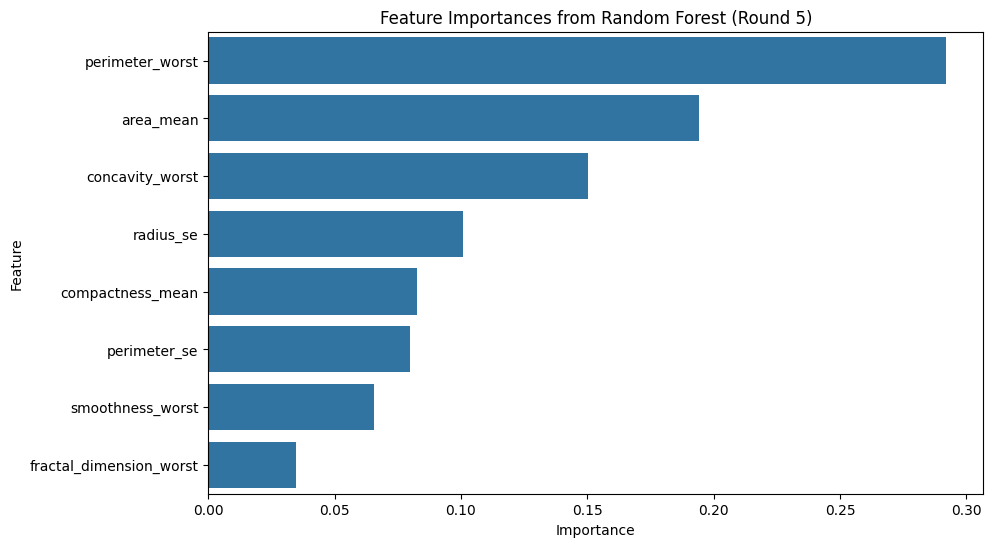

In [ ]:
# Extract feature importances from the best Random Forest model (e.g., rf_model_r5)
# Check if the model exists and has feature_importances_

if 'rf_model_r5' in locals() and hasattr(rf_model_r5, 'feature_importances_'):
    feature_importances = pd.Series(rf_model_r5.feature_importances_, index=X_train.columns)
    sorted_feature_importances = feature_importances.sort_values(ascending=False)

    print("\nFeature Importances from Random Forest (Round 5) (rf_model_r5):")
    display(sorted_feature_importances)

    # Visualize feature importances
    import matplotlib.pyplot as plt
    import seaborn as sns

    plt.figure(figsize=(10, 6))
    sns.barplot(x=sorted_feature_importances.values, y=sorted_feature_importances.index)
    plt.title('Feature Importances from Random Forest (Round 5)')
    plt.xlabel('Importance')
    plt.ylabel('Feature')
    plt.show()
else:
    print("Random Forest model (rf_model_r5) or its feature importances not found.")
